# 03 — Imbalance-Handling Techniques

**Goal:** hold the model fixed (Logistic Regression) and change *only* the imbalance technique, so any difference in score is caused by the technique.

| Technique | What it does | Trade-off |
|---|---|---|
| None | Train on raw data | Model biased toward "legit" |
| Class weights | Penalise mistakes on fraud more in the loss (`class_weight='balanced'`) | No data changed; can over-predict fraud |
| Random undersampling | Delete legit rows until 1:1 | Fast, but throws away ~99.8% of legit data |
| SMOTE | Create synthetic frauds by interpolating between real fraud neighbours | More fraud examples; synthetic points can add noise |

Then a **leakage demo**: what happens if you SMOTE *before* cross-validation — the most common mistake in this exact project.

In [1]:
import sys
sys.path.append("..")   # so `src` is importable from notebooks/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from imblearn.over_sampling import SMOTE

from src.config import REPORTS_DIR, FIGURES_DIR, RANDOM_STATE
from src.utils import load_splits, build_pipeline, cv_evaluate, get_preprocessor, get_cv, SCORING

X_train, X_test, y_train, y_test = load_splits()   # X_test / y_test NOT used in this notebook
print(f"Train: {len(y_train):,} rows, {y_train.sum()} frauds")

Train: 226,980 rows, 378 frauds


## 1. Benchmark the four techniques (5-fold stratified CV)

In [2]:
def logreg(**kw):
    return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **kw)

experiments = {
    "None":           build_pipeline(logreg()),
    "Class weights":  build_pipeline(logreg(class_weight="balanced")),
    "Undersampling":  build_pipeline(logreg(), sampler_name="undersample"),
    "SMOTE":          build_pipeline(logreg(), sampler_name="smote"),
}

rows = []
for name, pipe in experiments.items():
    print(f"Running: {name} ...")
    rows.append(cv_evaluate(pipe, X_train, y_train, name=name))

tech = pd.DataFrame(rows).set_index("name")
tech[["pr_auc", "pr_auc_std", "roc_auc", "precision", "recall", "f1", "fit_time_s"]]

Running: None ...


Running: Class weights ...


Running: Undersampling ...


Running: SMOTE ...


,pr_auc,pr_auc_std,roc_auc,precision,recall,f1,fit_time_s
name,,,,,,,
None,0.7527,0.0312,0.9764,0.8676,0.6136,0.7168,0.7256
Class weights,0.7544,0.0265,0.9815,0.0604,0.9179,0.1133,1.2377
Undersampling,0.6024,0.1157,0.9810,0.0441,0.9126,0.0841,0.1466
SMOTE,0.7556,0.0242,0.9799,0.4034,0.8651,0.5488,0.9822


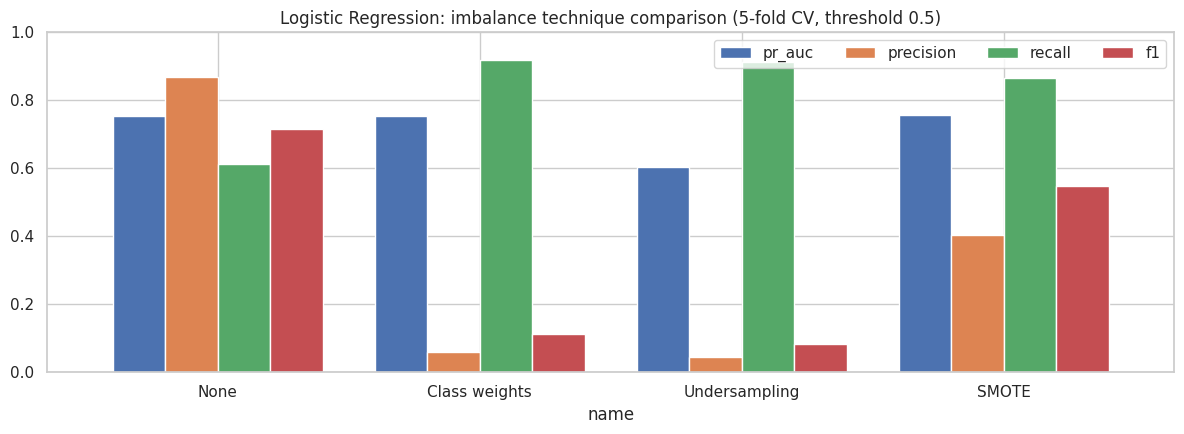

In [3]:
metrics = ["pr_auc", "precision", "recall", "f1"]
ax = tech[metrics].plot(kind="bar", figsize=(12, 4.5), rot=0, width=0.8)
ax.set_title("Logistic Regression: imbalance technique comparison (5-fold CV, threshold 0.5)")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", ncol=4)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_technique_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

### How to read this

Look at the **precision ↔ recall trade-off**, not a single number. What you should typically see:

- **Class weights / Undersampling** push recall up sharply (catch most frauds) but precision collapses — the model now flags thousands of legit transactions. Undersampling is usually the most extreme because each fold trains on only ~600 rows.
- **SMOTE (10%)** usually lands in between.
- **PR-AUC changes far less** than precision and recall do. That is an important insight: PR-AUC is threshold-free, and these techniques mostly *shift the model's probabilities* rather than making it fundamentally better at ranking fraud above legit. Much of the same effect can be had by **moving the decision threshold** — which we do in `05`.

So resampling isn't magic. Its main effect at a fixed 0.5 threshold is choosing a different point on the same precision/recall curve.

## 2. The leakage trap: SMOTE before cross-validation

**Wrong way:** SMOTE the whole training set, then cross-validate.
Synthetic frauds are interpolations of real frauds. When the data is split into folds, a synthetic point can sit in the validation fold while its "parent" frauds sit in the training fold — so the model is validated on near-copies of what it trained on.

**Right way (what we did above):** SMOTE is a step inside the pipeline, so it runs only on each training fold.

In [4]:
# WRONG: resample first, then CV on the resampled data
X_scaled = get_preprocessor().fit_transform(X_train)
X_sm, y_sm = SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE).fit_resample(X_scaled, y_train)
leaky = cross_validate(logreg(), X_sm, y_sm, cv=get_cv(), scoring=SCORING)

leak_df = pd.DataFrame({
    "SMOTE inside CV (correct)": tech.loc["SMOTE", ["pr_auc", "precision", "recall", "f1"]],
    "SMOTE before CV (leaky)": {k: leaky[f"test_{k}"].mean() for k in ["pr_auc", "precision", "recall", "f1"]},
})
leak_df

,SMOTE inside CV (correct),SMOTE before CV (leaky)
pr_auc,0.7556,0.9523
precision,0.4034,0.9768
recall,0.8651,0.8654
f1,0.5488,0.9177


The leaky version looks much better — **and it's fake**. The validation folds are ~9% synthetic fraud (instead of 0.17% real fraud), and those synthetic points are easy to catch. On real, unseen data the model would perform like the "correct" column.

**Interview line:** *"Resampling must only ever touch training data. I put SMOTE inside an imblearn Pipeline so it's re-applied per CV fold, and I never resample the test set."*

In [5]:
tech.to_csv(REPORTS_DIR / "03_technique_results.csv")
leak_df.to_csv(REPORTS_DIR / "03_leakage_demo.csv")
print("Saved.")

Saved.
